In [1]:
import numpy as np
from netCDF4 import Dataset
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib import colors

import matplotlib.gridspec as gridspec
import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs
import iris.analysis.cartography

import iris
import iris.quickplot as qplt 
import iris.plot as iplt
iris.FUTURE.netcdf_promote=True
import iris.coord_categorisation
import string

from iris.analysis import stats
from iris.analysis import maths

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/matplotlib/ticker.py:1693: UserWarning: Steps argument should be a sequence of numbers
increasing from 1 to 10, inclusive. Behavior with
values outside this range is undefined, and will
raise a ValueError in future versions of mpl.
  warnings.warn('Steps argument should be a sequence of numbers\n'


In [2]:
## Upload obs
#path_obs_t = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/woa23_temp_1971-2000_v2.nc'
#t_constraint_obs = iris.Constraint(cube_func=lambda cube: cube.var_name == 't_an')
#t_obs = iris.load_cube(path_obs_t, t_constraint_obs) 
#t_obs = iris.util.squeeze(t_obs)

In [2]:
## Upload PI
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path2 = '/nfs/hera1/ee22kvcs/work/nc/xpzed/datam/pg/'
path3 = '/nfs/hera1/ee22kvcs/KCM/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['thetao_Omon_ACCESS-ESM1-5_piControl_r1i1p1f1_gn_100101-110012_100yr_mean_regridded_360x385_intlevel.nc',
                   'temp_xpzed_pg_5021-5120_regridded_385x360_ann_mean_intlevel.nc',
                   'thetao_Omon_IPSL-CM6A-LR_piControl_r1i2p1f1_gn_195001-204912_regridded_100yr_mean_385x360_intlevel.nc',
                   'H0K_ym_6401_6500.codeT_regridded_360x385_100yr_mean_intlevel.nc',
                   'thetao_Omon_MIROC-ES2L_piControl_r1i1p1f2_gr1_225001-234912_regridded_100yr_mean_385x360_intlevel.nc',
                   'templvl.NBF1850OC_f19_tn11_02.micom.hy.1600-1699_regridded_ann_mean_intlevel.nc',
                   'thetao_Omon_NorESM2-LM_piControl_r1i1p1f1_gr_200101-210012_regridded_100yr_mean_intlevel.nc']

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'thetao'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'temp'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'thetao'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'thetao'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'templvl'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'thetao')]
PI_models = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path2+names_models_pi[i], constraints[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path3+names_models_pi[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    PI_models.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'areacello', referenced by netCDF variable 'thetao'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'volcello', referenced by netCDF variable 'thetao'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: 

In [3]:
## Upload LIG
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path2 = '/nfs/hera1/ee22kvcs/work/nc/xpzec/datam/pg/'
path3 = '/nfs/hera1/ee22kvcs/KCM/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_lig = ['thetao_Omon_ACCESS-ESM1-5_lig127k_r1i1p1f1_gn_100101-110012_100yr_mean_regridded_360x385_intlevel.nc',
                    'temp_xpzeco_pg_6651-6750_regridded_385x360_ann_mean_intlevel.nc',
                    'thetao_Omon_IPSL-CM6A-LR_lig127k_r1i1p1f1_gn__23000101_23991231_1M_thetao_regridded_385x360_100yr_mean_intlevel.nc',
                    'E7C_ym_4901_5000.codeT_regridded_360x385_100yr_mean_intlevel.nc',
                    'thetao_Omon_MIROC-ES2L_lig127k_r1i1p1f2_gr1_330001-339912_regridded_100yr_mean_385x360_intlevel.nc',
                    'templvl.NBF1850OC_f19_tn11_01_127ka.micom.hy.1600-1699_regridded_ann_mean_intlevel.nc',
                    'thetao_Omon_NorESM2-LM_lig127k_r1i1p1f1_gr_210101-220012_regridded_100yr_mean_intlevel.nc']

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'thetao'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'temp'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'thetao'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'thetao'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'templvl'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'thetao')]
LIG_models = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path2+names_models_lig[i], constraints[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path3+names_models_lig[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_lig[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    LIG_models.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'areacello', referenced by netCDF variable 'thetao'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'volcello', referenced by netCDF variable 'thetao'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: 

In [4]:
### Open masks
## Models
path_mask_atl = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Atlantic_ocean_NorESM2-LM.nc'
path_mask_pac = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Pacific_ocean_NorESM2-LM.nc'
path_mask_ind = '/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Mask_Indian_ocean_NorESM2-LM.nc'
masks = iris.Constraint(cube_func=lambda cube: cube.var_name == 'mask')
## Open
atlantic_mask = iris.load_cube(path_mask_atl, masks)
pacific_mask = iris.load_cube(path_mask_pac, masks)
indian_mask = iris.load_cube(path_mask_ind, masks)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdty

### Setup the data files

In [5]:
def broadcast_masks_to_models(models, atlantic_mask, pacific_mask, indian_mask):
    "Input: lists iof iris cubes.Output: dictionary of broadcasted mask cubes by basin"
    broadcasted_masks = {"atlantic": [], "pacific": [], "indian": []}
    
    for model in models:
        shape = model.shape  # (depth, lat, lon) or similar
        
        # Broadcast each mask
        atl_broadcast = np.broadcast_to(atlantic_mask.data, shape)
        pac_broadcast = np.broadcast_to(pacific_mask.data, shape)
        ind_broadcast = np.broadcast_to(indian_mask.data, shape)
        
        # Replace NaNs with masked values
        atl_masked = np.ma.masked_invalid(atl_broadcast)
        pac_masked = np.ma.masked_invalid(pac_broadcast)
        ind_masked = np.ma.masked_invalid(ind_broadcast)
        
        # Create cubes with the same metadata as the model
        broadcasted_masks["atlantic"].append(model.copy(data=atl_masked))
        broadcasted_masks["pacific"].append(model.copy(data=pac_masked))
        broadcasted_masks["indian"].append(model.copy(data=ind_masked))
    
    return broadcasted_masks

In [6]:
masks_PI = broadcast_masks_to_models(PI_models, atlantic_mask, pacific_mask, indian_mask)

In [7]:
masks_LIG = broadcast_masks_to_models(LIG_models, atlantic_mask, pacific_mask, indian_mask)

In [8]:
### PI data
atlantic_masked_PI_models = [m * mask for m, mask in zip(PI_models, masks_PI["atlantic"])]
indian_masked_PI_models = [m * mask for m, mask in zip(PI_models, masks_PI["indian"])]
pacific_masked_PI_models = [m * mask for m, mask in zip(PI_models, masks_PI["pacific"])]
#### PI Zonal means
atl_an_zmean_tem_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_PI_models]
ind_an_zmean_tem_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_PI_models]
pac_an_zmean_tem_PI = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_PI_models]

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:988: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(self.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:1017: UserWarning: Collapsing a non-contiguous coordinate. Metadata may not be fully descriptive for 'longitude'.
  warnings.warn(msg.format(self.name()))


In [9]:
### LIG data
atlantic_masked_LIG_models = [m * mask for m, mask in zip(LIG_models, masks_LIG["atlantic"])]
indian_masked_LIG_models = [m * mask for m, mask in zip(LIG_models, masks_LIG["indian"])]
pacific_masked_LIG_models = [m * mask for m, mask in zip(LIG_models, masks_LIG["pacific"])]
#### LIG Zonal means
atl_an_zmean_tem_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in atlantic_masked_LIG_models]
ind_an_zmean_tem_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in indian_masked_LIG_models]
pac_an_zmean_tem_LIG = [n.collapsed('longitude', iris.analysis.MEAN) for n in pacific_masked_LIG_models]

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:988: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(self.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/coords.py:1017: UserWarning: Collapsing a non-contiguous coordinate. Metadata may not be fully descriptive for 'longitude'.
  warnings.warn(msg.format(self.name()))


### Differences

In [10]:
### Differences
dif_tem_atl = []
dif_tem_pac = []
dif_tem_ind = []

for i in range (7):
    dif_atl = atl_an_zmean_tem_LIG[i].data-atl_an_zmean_tem_PI[i].data
    dif_pac = pac_an_zmean_tem_LIG[i].data-pac_an_zmean_tem_PI[i].data
    dif_ind = ind_an_zmean_tem_LIG[i].data-ind_an_zmean_tem_PI[i].data

    dif_atl_cube = atl_an_zmean_tem_PI[i].copy(data = dif_atl)
    dif_pac_cube = pac_an_zmean_tem_PI[i].copy(data = dif_pac)
    dif_ind_cube = ind_an_zmean_tem_PI[i].copy(data = dif_ind)
    
    dif_tem_atl.append(dif_atl_cube)
    dif_tem_pac.append(dif_pac_cube)
    dif_tem_ind.append(dif_ind_cube)

/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3337: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _data[indx] = dval
/nfs/see-fs-01_users/mlzp121/.local/lib/python3.5/site-packages/numpy/ma/core.py:3340: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  _mask[indx] = mval


#### Plot

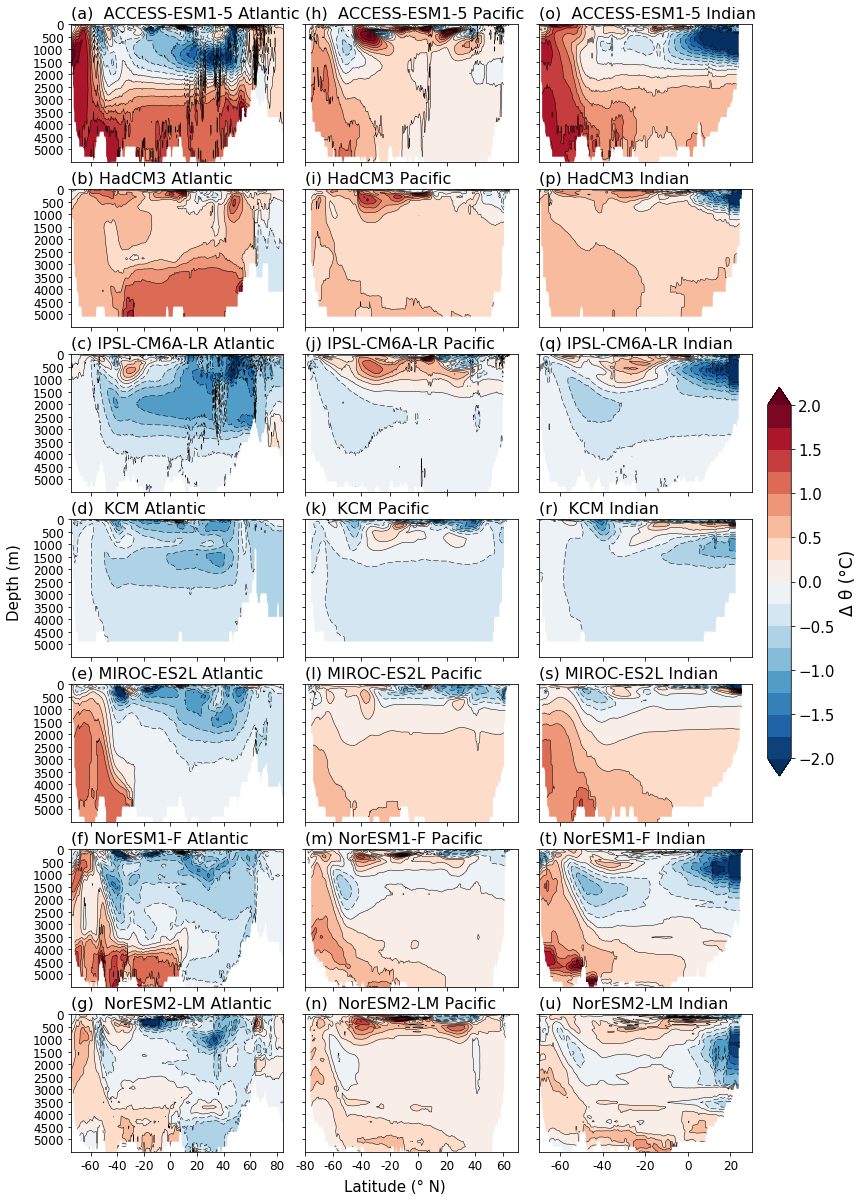

In [11]:
fig = plt.figure(figsize=(11, 18))

n_models = 7
n_basins = 3

axes = np.empty((n_models, n_basins), dtype=object)
for i in range(n_models):
    for j in range(n_basins):
        idx = i * n_basins + j + 1
        axes[i, j] = fig.add_subplot(n_models, n_basins, idx)

model_names = [' ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', ' KCM', 'MIROC-ES2L', 'NorESM1-F', ' NorESM2-LM']
basin_names = ['Atlantic', 'Pacific', 'Indian']
simulations_list = [dif_tem_atl, dif_tem_pac, dif_tem_ind]
depth = ['depth', 'depth_1', 'Vertical T levels', 'plev', 'ocean sigma over z coordinate', 'depth', 'depth']

# Letters: column 1 = a-g, column 2 = h-n, column 3 = o-u
letters = list(string.ascii_lowercase)
letter_cols = [letters[0:7], letters[7:14], letters[14:21]]

levels = np.arange(-2, 2+.25, .25)
levels2 = np.arange(-2, 2+.25, .25)

im = None

for j, simulations in enumerate(simulations_list):
    for n in range(n_models):
        ax = axes[n, j]
        ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
        ax.tick_params(axis='x', labelsize=13)
        ax.tick_params(axis='y', labelsize=13)
        ax.set_ylim(0, 5500)
        
        # ticks for all, labels only on left column
        ax.set_yticks(np.arange(0, 5000+500, 500))
        if j == 0:
            ax.tick_params(axis='y', labelsize=12)
        else:
            ax.set_yticklabels([])

        if n == n_models - 1:
            ax.set_xticklabels(ax.get_xticks(), fontsize=12)
        else:
            ax.set_xticklabels([])
        #----------------------------------------------
        if j == 0:
            ax.set_xlim(-75, 85)
        elif j == 1:
            ax.set_xlim(-80, 70)
        else:
            ax.set_xlim(-70, 30)

        letter = letter_cols[j][n]
        title_str = "(" + letter + ") " + model_names[n] + " " + basin_names[j]
        ax.set_title(title_str, fontsize=16, loc='left')
        
        #-----------------------------------------------
        im = iplt.contourf(simulations[n], coords=['latitude', depth[n]], axes=ax, levels=levels, cmap='RdBu_r', extend='both')
        im2 = iplt.contour(simulations[n], coords=['latitude', depth[n]], axes=ax, colors='k', levels=levels2, linewidths=0.5)

        if n in [1, 2, 3, 4, 5]:
            ax.invert_yaxis()

# shared colorbar
fig.subplots_adjust(left=0.12, right=0.88, top=0.95, bottom=0.05, wspace=0.1, hspace=0.1)
cbar_ax = fig.add_axes([0.97, 0.35, 0.03, 0.3])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.ax.set_ylabel(r'Δ θ (°C)', size=17)
cbar.ax.tick_params(labelsize=15)

# Shared axis labels
fig.text(0.01, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=15)
fig.text(0.5, 0.03, 'Latitude (° N)', ha='center', fontsize=15)

plt.subplots_adjust(left=0.09, bottom=0.06, right=0.95, top=0.93, wspace=0.1, hspace=0.2)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Thetao_diff_3basins_v2.png', bbox_inches='tight', dpi=300, format='png')
plt.show()

### MMM difference

In [12]:
### PI
MMM_dif_atl = sum([dif_tem_atl[i].data for i in range(np.size(dif_tem_atl))])/7
MMM_dif_pac = sum([dif_tem_pac[i].data for i in range(np.size(dif_tem_pac))])/7
MMM_dif_ind = sum([dif_tem_ind[i].data for i in range(np.size(dif_tem_ind))])/7
## Convert arrays to iris cubes
MMM_dif_atl_cube = dif_tem_atl[0].copy(data = MMM_dif_atl)
MMM_dif_pac_cube = dif_tem_pac[0].copy(data = MMM_dif_pac)
MMM_dif_ind_cube = dif_tem_ind[0].copy(data = MMM_dif_ind)

#### Spread

In [13]:
def calculate_spread(dif_list, threshold=0, min_models=5):
    "Spread of the difference, where min_models agree on change above or below a threshold"
    # Model differences in a 3D array (models, lat, depth)
    model_difs = np.array([dif_list[i].data for i in np.arange(np.size(dif_tem_atl))])

    # Count models exceeding thresholds
    positive_count = np.sum(model_difs > threshold, axis=0)
    negative_count = np.sum(model_difs < -threshold, axis=0)

    # Agreement mask
    agreement_mask = (positive_count >= min_models) | (negative_count >= min_models)

    # Non-agreement mask
    non_agreement_mask = ~agreement_mask

    return agreement_mask, non_agreement_mask

In [14]:
agreement_atl_thresh, non_agreement_atl_thresh = calculate_spread(dif_tem_atl, threshold=0, min_models=5)
agreement_ind_thresh, non_agreement_ind_thresh = calculate_spread(dif_tem_ind, threshold=0, min_models=5)
agreement_pac_thresh, non_agreement_pac_thresh = calculate_spread(dif_tem_pac, threshold=0, min_models=5)

#### MMM diff plot

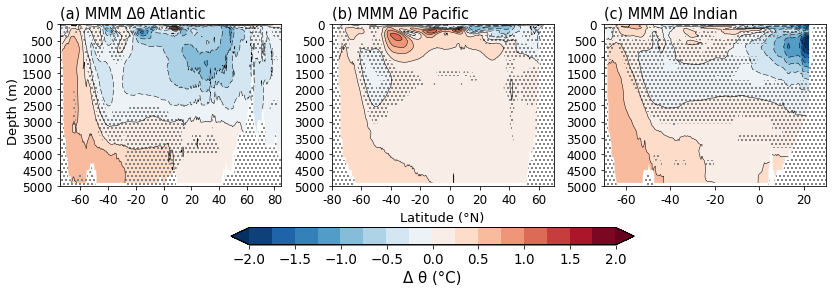

In [15]:
#### Plot zmeans PI and LIG MMM Atlantic
fig = plt.figure(figsize=(14, 3))
axes = []

# Create subplots
ax1 = fig.add_axes([0.05, 0.15, 0.22, 0.75])  # [left, bottom, width, height]
ax2 = fig.add_axes([0.32, 0.15, 0.22, 0.75])
ax3 = fig.add_axes([0.59, 0.15, 0.22, 0.75])
axes = [ax1, ax2, ax3]

titles = ['(a) MMM Δθ Atlantic', '(b) MMM Δθ Pacific', '(c) MMM Δθ Indian']
simulations = [MMM_dif_atl_cube, MMM_dif_pac_cube, MMM_dif_ind_cube]
depth = ['depth', 'depth', 'depth']
spread = [MMM_dif_atl_cube, MMM_dif_pac_cube, MMM_dif_ind_cube]
non_agreement = [non_agreement_atl_thresh, non_agreement_pac_thresh, non_agreement_ind_thresh]


for (ax, t, n) in zip(axes, titles, range(np.size(simulations))):
    ax.set_xticks([-80, -60, -40, -20, 0, 20, 40, 60, 80])
    ax.set_xticklabels([-80, -60, -40, -20, 0, 20, 40, 60, 80])
    ax.set_yticks(np.arange(0, 5000+500, 500))
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    ax.set_ylim(0, 5000)
    #ax.set_xlim(-80, 80)
    if n == 2: ## Indian
        ax.set_xlim(-70, 30)
    elif n == 1: ## Pacific
        ax.set_xlim(-80, 70)
    else: ## Atlantic
        ax.set_xlim(-75, 85)
    
    ax.set_title(t, fontsize=14.5, loc='left')
    
    levels = np.concatenate([np.arange(-2, 0, 2), np.arange(0, 9, 2), np.arange(12, 34, 4)])
    levels2 = np.concatenate([np.arange(-2, 0, 2), np.arange(0, 9, 1), np.arange(12, 34, 4)])
    
    im = iplt.contourf(simulations[n], coords=['latitude', depth[n]], axes = ax, levels = np.arange(-2, 2+.25, .25), cmap = 'RdBu_r', extend = 'both')
    im2 = iplt.contour(simulations[n], coords=['latitude', depth[n]], axes=ax, colors='k', levels = np.arange(-2, 2+.25, .25), linewidths=0.5)

    # Colourbar
    cbar_ax = fig.add_axes([0.22, -0.12, 0.40, 0.08])  # [left, bottom, width, height]
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
    cbar.ax.set_xlabel('Δ θ (°C)', size=15)
    cbar.ax.tick_params(labelsize=13.5)
    # Hatching
    mpl.rcParams['hatch.color'] = 'gray'
    for i in range(np.size(spread)):
        ax.contourf(spread[i].coord('latitude').points, spread[i].coord('depth').points, non_agreement[n], 
                    levels=[0.5, 1.5], hatches=['...'], alpha=0, colors='none')
        
fig.text(-0.002, 0.5, 'Depth (m)', va='center', rotation='vertical', fontsize=13)
fig.text(0.43, -0.01, 'Latitude (°N)', ha='center', fontsize=13)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/Thetao_MMM_zonally_mean_diff_by_basin2.png', bbox_inches='tight', dpi=300, format='png')
plt.show()